# SpaceX Falcon 9 — Machine Learning

IBM Data Science Capstone | Booster landing classification

## Libraries

I used scikit-learn to prepare the features, train four classifiers, and compare their results.

In [2]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score,
                             RocCurveDisplay, PrecisionRecallDisplay)

RANDOM_STATE = 42
print("Libraries imported successfully")

Libraries imported successfully


## Dataset overview

I used the same processed historical dataset as in the previous notebooks. The target is `Class`, which contains two values: 0 and 1.

In [3]:
data_path = Path("spacex_launches_processed.csv")
if not data_path.exists():
    try:
        from google.colab import files
        print("Upload spacex_launches_processed.csv from Notebook 01")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Place spacex_launches_processed.csv in the working directory")

df = pd.read_csv(data_path)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Class distribution:")
print(df["Class"].value_counts(dropna=False).sort_index())
display(df.head())

Upload spacex_launches_processed.csv from Notebook 01


Saving spacex_launches_processed.csv to spacex_launches_processed.csv
Dataset shape: (90, 18)
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']
Class distribution:
Class
0    11
1    79
Name: count, dtype: int64


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,1
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,1
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,1
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,1


## Selecting features

I kept payload mass, booster flight history, launch site, orbit and a few booster-related fields. I excluded `Outcome` because it directly defines the target, and `LandingPad` because it may contain information that would not be available before the landing.

In [4]:
target = "Class"
numeric_candidates = ["PayloadMass", "Flights", "Block", "ReusedCount"]
categorical_candidates = ["LaunchSite", "Orbit", "GridFins", "Reused", "Legs"]
features = numeric_candidates + categorical_candidates
missing = [c for c in features + [target] if c not in df.columns]
if missing:
    raise ValueError(f"Required fields missing: {missing}")
assert df[target].notna().all(), "Missing target values"
assert set(df[target].unique()) == {0,1}, "Expected both binary classes 0 and 1"
assert df[target].value_counts().min() >= 5, "Too few minority-class examples for 5-fold CV"
print("Selected predictors:", features)
print("Excluded potential leakage fields:", [c for c in ["Outcome","LandingPad","FlightNumber","Date","Serial"] if c in df])
print("Missing values in selected fields:\n", df[features].isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Selected predictors: ['PayloadMass', 'Flights', 'Block', 'ReusedCount', 'LaunchSite', 'Orbit', 'GridFins', 'Reused', 'Legs']
Excluded potential leakage fields: ['Outcome', 'LandingPad', 'FlightNumber', 'Date', 'Serial']
Missing values in selected fields:
 PayloadMass    0
Flights        0
Block          0
ReusedCount    0
LaunchSite     0
Orbit          0
GridFins       0
Reused         0
Legs           0
dtype: int64
Duplicate rows: 0


## Training and test data

I used a stratified 80/20 split so that both landing classes are represented in the training and test sets. I kept the test data separate during model selection.

In [5]:
X = df[features].copy()
y = df[target].astype(int)
for col in categorical_candidates:
    X[col] = X[col].astype("string").fillna("Missing").astype(str)
for col in numeric_candidates:
    X[col] = pd.to_numeric(X[col], errors="coerce")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Training class counts:\n", y_train.value_counts().sort_index())
print("Test class counts:\n", y_test.value_counts().sort_index())
assert set(X_train.index).isdisjoint(X_test.index)

Train: (72, 9) Test: (18, 9)
Training class counts:
 Class
0     9
1    63
Name: count, dtype: int64
Test class counts:
 Class
0     2
1    16
Name: count, dtype: int64


## Preprocessing

I filled missing numeric values with the median and scaled the numeric features. Categorical variables were one-hot encoded. I placed these transformations inside pipelines so they are fitted only on the training folds.

In [6]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_candidates),
    ("categorical", categorical_transformer, categorical_candidates)
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Preprocessing and 5-fold stratified CV configured")

Preprocessing and 5-fold stratified CV configured


## Models

I compared Logistic Regression, Support Vector Machine, Decision Tree and K-Nearest Neighbors. I tried a small set of hyperparameters for each model.

In [7]:
candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
        {"model__C": [0.1, 1, 10]}
    ),
    "Support Vector Machine": (
        SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE),
        {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"]}
    ),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"model__max_depth": [2, 3, 5, None], "model__min_samples_leaf": [1, 3]}
    ),
    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 7], "model__weights": ["uniform", "distance"]}
    )
}
print("Models:", list(candidates))

Models: ['Logistic Regression', 'Support Vector Machine', 'Decision Tree', 'K-Nearest Neighbors']


## Cross-validation

I used stratified five-fold cross-validation and selected hyperparameters using balanced accuracy. This metric is more informative than accuracy alone because the dataset contains many more Class 1 records.

In [8]:
searches = {}
cv_rows = []
for name, (estimator, param_grid) in candidates.items():
    pipeline = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="balanced_accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )
    search.fit(X_train, y_train)
    searches[name] = search
    cv_rows.append({"Model": name,
                    "CV Balanced Accuracy": search.best_score_,
                    "Best Parameters": str(search.best_params_)})
    print(f"{name}: CV balanced accuracy = {search.best_score_:.3f}")
cv_results = pd.DataFrame(cv_rows).sort_values("CV Balanced Accuracy", ascending=False).reset_index(drop=True)
display(cv_results)

Logistic Regression: CV balanced accuracy = 0.656
Support Vector Machine: CV balanced accuracy = 0.679
Decision Tree: CV balanced accuracy = 0.837
K-Nearest Neighbors: CV balanced accuracy = 0.618


,Model,CV Balanced Accuracy,Best Parameters
0,Decision Tree,0.836538,"{'model__max_depth': 2, 'model__min_samples_le..."
1,Support Vector Machine,0.679487,"{'model__C': 10, 'model__kernel': 'linear'}"
2,Logistic Regression,0.656410,{'model__C': 10}
3,K-Nearest Neighbors,0.617949,"{'model__n_neighbors': 3, 'model__weights': 'd..."


## Test-set evaluation

After tuning, I evaluated each model on the held-out test set. I compared accuracy, balanced accuracy, precision, recall, F1-score, ROC-AUC and average precision.

In [9]:
test_rows = []
for name, search in searches.items():
    pred = search.predict(X_test)
    scores = search.predict_proba(X_test)[:, 1]
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Precision (Class 1)": precision_score(y_test, pred, zero_division=0),
        "Recall (Class 1)": recall_score(y_test, pred, zero_division=0),
        "F1 (Class 1)": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Average Precision (Class 1)": average_precision_score(y_test, scores)
    })
test_results = pd.DataFrame(test_rows).sort_values("Balanced Accuracy", ascending=False).reset_index(drop=True)
display(test_results.round(3))
print("Class 1 prevalence in test set:", round(y_test.mean(),3), "(AP no-skill reference)")

,Model,Accuracy,Balanced Accuracy,Precision (Class 1),Recall (Class 1),F1 (Class 1),ROC-AUC,Average Precision (Class 1)
0,Logistic Regression,0.833,0.906,1.000,0.812,0.897,0.906,0.988
1,K-Nearest Neighbors,0.833,0.688,0.933,0.875,0.903,0.656,0.917
2,Support Vector Machine,0.722,0.625,0.923,0.750,0.828,0.875,0.984
3,Decision Tree,0.667,0.594,0.917,0.688,0.786,0.766,0.958


Class 1 prevalence in test set: 0.889 (AP no-skill reference)


## Selected model

I selected the model with the highest training cross-validation balanced accuracy, rather than choosing a model based on the test results.

In [10]:
best_name = cv_results.loc[0, "Model"]
best_search = searches[best_name]
best_model = best_search.best_estimator_
y_pred = best_model.predict(X_test)
y_score = best_model.predict_proba(X_test)[:, 1]
print("Selected by training CV:", best_name)
print("Best parameters:", best_search.best_params_)
print("Held-out classification report:\n")
print(classification_report(y_test, y_pred, labels=[0,1], target_names=["Class 0","Class 1"], zero_division=0))

Selected by training CV: Decision Tree
Best parameters: {'model__max_depth': 2, 'model__min_samples_leaf': 1}
Held-out classification report:

              precision    recall  f1-score   support

     Class 0       0.17      0.50      0.25         2
     Class 1       0.92      0.69      0.79        16

    accuracy                           0.67        18
   macro avg       0.54      0.59      0.52        18
weighted avg       0.83      0.67      0.73        18



## Confusion matrix

The confusion matrix shows how many observations from each class were predicted correctly or incorrectly.

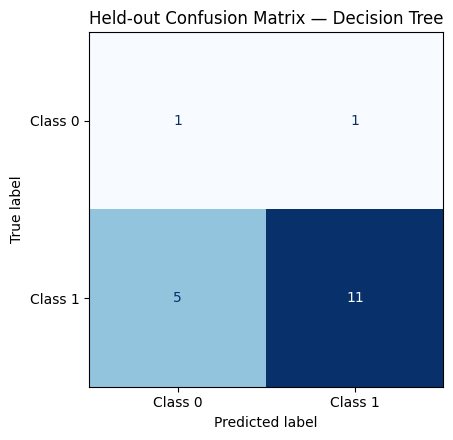

In [11]:
fig, ax = plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0,1],
    display_labels=["Class 0","Class 1"], cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Held-out Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig("07_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## ROC and precision–recall curves

I plotted both curves for the selected model. The precision–recall curve includes the Class 1 prevalence baseline, which is important because the dataset is imbalanced.

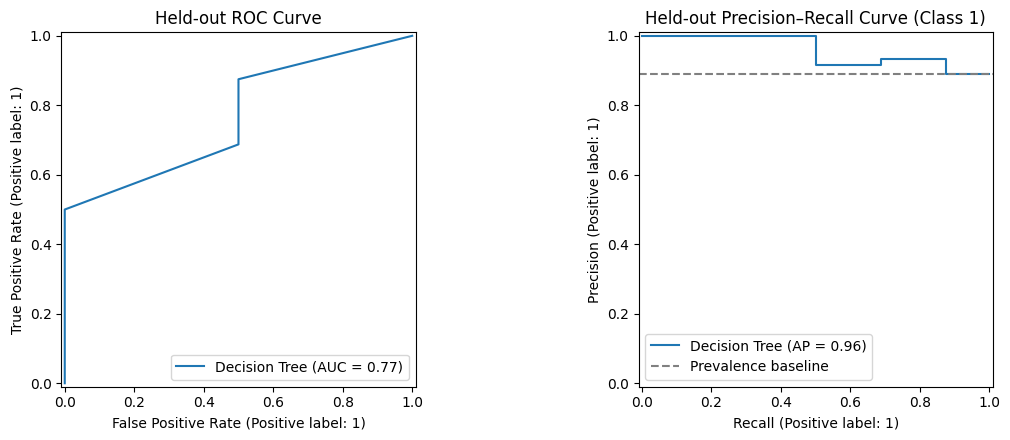

In [12]:
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[0], name=best_name)
axes[0].set_title("Held-out ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, y_score, ax=axes[1], name=best_name)
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Prevalence baseline")
axes[1].legend()
axes[1].set_title("Held-out Precision–Recall Curve (Class 1)")
plt.tight_layout()
plt.savefig("07_roc_pr_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## Model comparison

This chart compares the mean cross-validation balanced accuracy for the four models.

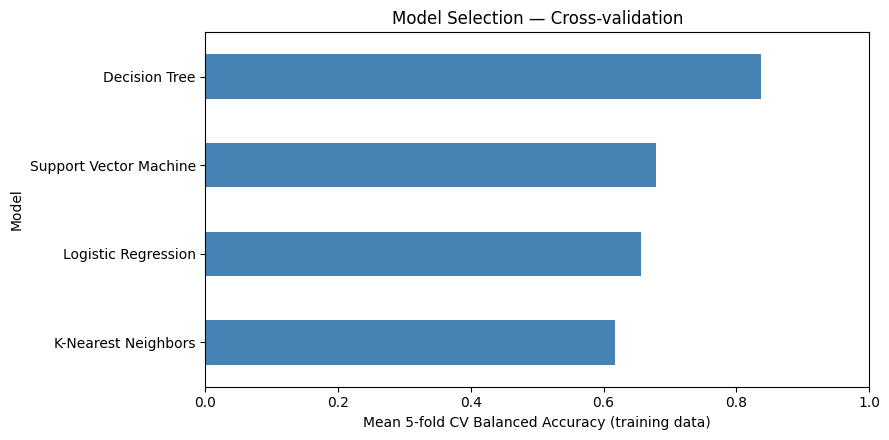

In [13]:
ax = cv_results.sort_values("CV Balanced Accuracy").plot.barh(
    x="Model", y="CV Balanced Accuracy", legend=False, figsize=(9,4.5), color="steelblue")
ax.set_xlabel("Mean 5-fold CV Balanced Accuracy (training data)")
ax.set_xlim(0,1)
ax.set_title("Model Selection — Cross-validation")
plt.tight_layout()
plt.savefig("07_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## Saving results

I saved the comparison tables, model, plots and a short JSON summary so I can use the verified results in the final presentation.

In [14]:
cv_results.to_csv("07_cv_model_comparison.csv", index=False)
test_results.to_csv("07_test_model_metrics.csv", index=False)
joblib.dump(best_model, "07_best_spacex_model.joblib")

summary = {
    "dataset_rows": int(len(df)),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "class_0_count": int((y==0).sum()),
    "class_1_count": int((y==1).sum()),
    "selected_model": best_name,
    "cv_balanced_accuracy": float(best_search.best_score_),
    "test_balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "test_roc_auc": float(roc_auc_score(y_test, y_score)),
    "test_average_precision": float(average_precision_score(y_test, y_score))
}
import json
Path("07_results_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))
print("Saved comparison tables, plots, model and summary.")

{
  "dataset_rows": 90,
  "train_rows": 72,
  "test_rows": 18,
  "class_0_count": 11,
  "class_1_count": 79,
  "selected_model": "Decision Tree",
  "cv_balanced_accuracy": 0.8365384615384617,
  "test_balanced_accuracy": 0.59375,
  "test_accuracy": 0.6666666666666666,
  "test_roc_auc": 0.765625,
  "test_average_precision": 0.9579861111111111
}
Saved comparison tables, plots, model and summary.


## Exporting the results

This optional cell creates a ZIP containing the outputs from the current run.

In [15]:
# Run only if you want all artifacts in one ZIP.
import zipfile
outputs = ["07_cv_model_comparison.csv", "07_test_model_metrics.csv",
           "07_best_spacex_model.joblib", "07_results_summary.json",
           "07_confusion_matrix.png", "07_roc_pr_curves.png", "07_model_comparison.png"]
with zipfile.ZipFile("07_SpaceX_ML_Results.zip", "w", compression=zipfile.ZIP_DEFLATED) as z:
    for filename in outputs:
        z.write(filename)
print("Created 07_SpaceX_ML_Results.zip")
try:
    from google.colab import files
    print("ZIP ready: 07_SpaceX_ML_Results.zip (download from the Colab Files panel)")
except ImportError:
    print("ZIP saved locally")

Created 07_SpaceX_ML_Results.zip
ZIP ready: 07_SpaceX_ML_Results.zip (download from the Colab Files panel)
